In [18]:
import pandas as pd
import numpy as np
import h5py as h5

import datetime as datetime
import matplotlib as plot

In [19]:
run_results = pd.read_pickle('./run_logs/results_20230410_1456.pkl')
run_results.set_index("int_length", inplace=True)

In [43]:
run_results.head()

,sim_number,clock_time
int_length,,
1000000.0,0000,156.247267
2500000.0,0000,392.005874
5000000.0,0000,783.192200
7500000.0,0000,1170.567606
10000000.0,0000,1589.181207


sim_number
0000    AxesSubplot(0.125,0.11;0.775x0.77)
0001    AxesSubplot(0.125,0.11;0.775x0.77)
0002    AxesSubplot(0.125,0.11;0.775x0.77)
0003    AxesSubplot(0.125,0.11;0.775x0.77)
0004    AxesSubplot(0.125,0.11;0.775x0.77)
0005    AxesSubplot(0.125,0.11;0.775x0.77)
Name: clock_time, dtype: object

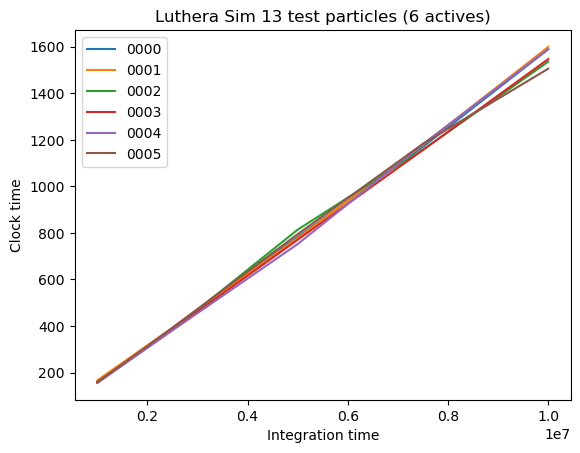

In [44]:
run_results.groupby("sim_number")["clock_time"].plot(legend=True, xlabel="Integration time", ylabel="Clock time", 
                                                     title="Luthera Sim 13 test particles (6 actives)")


In [45]:
avg_clock_time = run_results.groupby("int_length")["clock_time"].mean()

int_time = [float(int_time) for int_time in avg_clock_time.index]

lin_fit = np.polyfit(int_time, avg_clock_time,1)
reg_fun = np.poly1d(lin_fit)
print(reg_fun)

 
0.0001561 x + 0.7927


In [46]:
print(reg_fun(int_time))
print(f'Time to run 1.e6 {datetime.timedelta(seconds=reg_fun(1.e6))}')
print(f'Time to run 1.e7 {datetime.timedelta(seconds=reg_fun(1.e7))}')
print(f'Time to run 1.e8 {datetime.timedelta(seconds=reg_fun(1.e8))}')
print(f'Time to run 1.e9 {datetime.timedelta(seconds=reg_fun(1.e9))}')

print(f'Time to run 2.25e9 {datetime.timedelta(seconds=reg_fun(2.25e9))}')
print(f'Time to run 4.5e9 {datetime.timedelta(seconds=reg_fun(4.5e9))}')

[ 156.85541429  390.94955899  781.10646681 1171.26337463 1561.42028246]
Time to run 1.e6 0:02:36.855414
Time to run 1.e7 0:26:01.420282
Time to run 1.e8 4:20:07.068964
Time to run 1.e9 1 day, 19:21:03.555781
Time to run 2.25e9 4 days, 1:32:22.009692
Time to run 4.5e9 8 days, 3:04:43.226734


In [7]:
luthera = pd.read_pickle('luthera_eph.pkl')

In [8]:
luthera.head()

,ast_name,X,Y,Z,VX,VY,VZ,sX,sY,sZ,sVX,sVY,sVZ
0,1303,3.359408,-0.452480,-1.186056,0.480819,3.064164,0.168282,8.701710e-08,3.175031e-07,4.760651e-08,2.755804e-07,7.268683e-08,9.934185e-08
1,11911,2.140391,1.429843,-0.830626,-2.270238,3.332010,-0.700615,3.203728e-07,4.665975e-07,1.742568e-07,5.539689e-07,4.036088e-07,3.522936e-07
2,16794,0.840324,-3.311674,0.736326,2.920928,1.010559,-0.893826,4.350451e-07,1.687924e-07,2.637303e-07,1.663809e-07,4.010379e-07,2.104587e-07
3,17840,2.750743,-0.702947,0.541571,1.328030,3.524747,-0.933713,1.709369e-07,4.277067e-07,1.138321e-07,5.257128e-07,1.538347e-07,1.150349e-07
4,26558,-2.853475,1.822653,0.823708,-2.041671,-2.390435,-0.657225,4.011603e-07,3.906963e-07,2.627875e-07,4.387526e-07,2.923667e-07,2.958762e-07


<AxesSubplot: xlabel='X', ylabel='Y'>

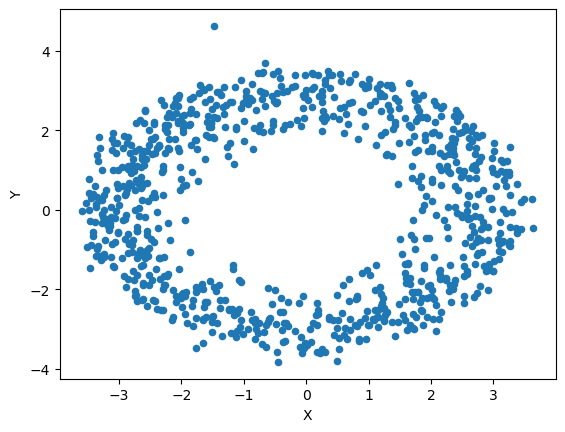

In [16]:
luthera[['X','Y','Z']].plot.scatter(x='X',y='Y')

<AxesSubplot: xlabel='X', ylabel='Z'>

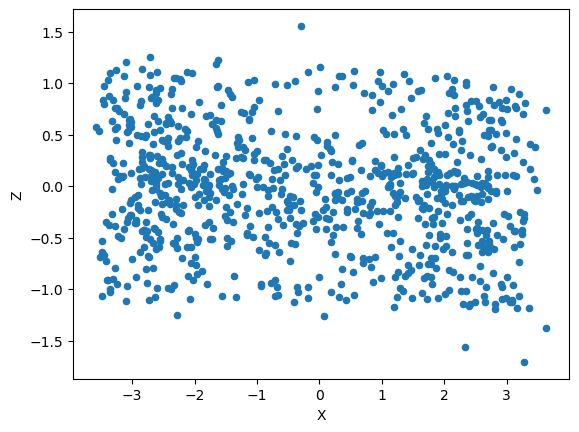

In [17]:
luthera[['X','Y','Z']].plot.scatter(x='X',y='Z')

<AxesSubplot: xlabel='Y', ylabel='Z'>

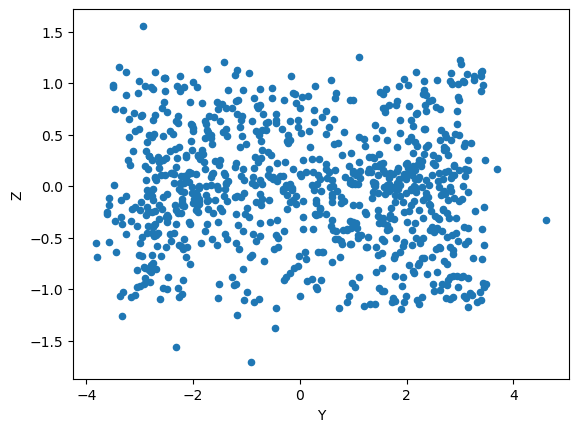

In [18]:
luthera[['X','Y','Z']].plot.scatter(x='Y',y='Z')

In [19]:
luthera[(luthera.Y > 4.0)]

,ast_name,X,Y,Z,VX,VY,VZ,sX,sY,sZ,sVX,sVY,sVZ
854,2012 QD29,-1.478304,4.622391,-0.329345,-0.000018,-0.000006,2.102605e-07,0.000003,8.221458e-07,0.000002,3.510010e-12,8.981724e-12,2.687414e-12


In [33]:
path = './run_logs/luthera_sim_20230410_1456_0000.h5'
luth_000_run = h5.File(path,"r")


In [34]:
luth_000_run.attrs.keys()


<KeysViewHDF5 ['clock_time', 'int_length', 'simulation']>

In [35]:
print(luth_000_run.attrs['clock_time'], luth_000_run.attrs['int_length'],luth_000_run.attrs['simulation'])


1589.182697057724 10000000.0 0000


In [36]:
luth_000_run.keys()

<KeysViewHDF5 ['integration_time_values', 'test_particle_values']>

In [37]:
int_values = luth_000_run['integration_time_values'][()]
part_values = luth_000_run['test_particle_values'][()]


In [38]:
int_values[0:10]

array([10000.        , 16282.81358854, 22565.62717708, 28848.44076562,
       35131.25435415, 41414.06794269, 47696.88153123, 53979.69511977,
       60262.50870831, 66545.32229685])

In [39]:
part_values.shape


(10000, 13, 9)

In [41]:
part_values[0][0][:]


array([-2.64296901,  0.32113256,  0.92417565, -0.08804749, -0.62330224,
       -0.04106024,  3.2066749 ,  0.12116884,  0.34068268])

In [42]:
part_values[-1][0][:]

array([-2.5450426 ,  2.3997384 , -0.41669603, -0.37545313, -0.30935734,
        0.13840688,  3.20509552,  0.13176711,  0.31374586])